In [34]:
import polars as pl
from datetime import date
import matplotlib.pyplot as plt
# Import requested libraries

In [3]:
df = pl.read_csv("../data/processed/online_retail_clean.csv", try_parse_dates = True)
# Read the dataset

In [4]:
df = df.with_columns(
    (pl.lit(date(2010, 12, 10)) - df["invoice_date"]).alias("recency")
)
# Calculate the recency of each customer's last purchase

In [5]:
frequency = df.group_by("customer_id").agg(
    pl.col("invoice").n_unique().alias("frequency")
)
# Calculate the number of unique invoices for each customer

In [6]:
df = df.with_columns(
    (pl.col("quantity") * pl.col("price")).alias("monetary")
)
# Calculate the monetary value of each transaction

In [7]:
customer_monetary = df.group_by("customer_id").agg(
    pl.col("monetary").sum().alias("total_monetary")
)
# Calculate the total monetary value for each customer

In [23]:
# Keep only positive-quantity transactions for RFM analysis.
df_rfm = df.filter(pl.col("quantity") > 0)

rfm = df_rfm.group_by("customer_id").agg(
    (date(2010, 12, 10) - pl.col("invoice_date").max()).dt.total_days().alias("recency"),
    pl.col("invoice").n_unique().alias("frequency"),
    pl.col("monetary").sum().alias("total_monetary")
)
rfm
# Calculate RFM metrics for each customer

customer_id,recency,frequency,total_monetary
i64,i64,u32,f64
13300,24,2,913.62
16325,60,9,3003.26
16846,213,2,628.09
18221,26,1,383.33
14095,358,1,2.95
…,…,…,…
15065,46,1,168.73
14612,51,1,877.7
16899,14,2,424.71


In [30]:
print(rfm["recency"].min())
print(rfm["recency"].max())
print(round(rfm["recency"].mean(),2))

1
374
91.27


In [32]:
print(rfm["frequency"].min())
print(rfm["frequency"].max())
print(round(rfm["frequency"].mean(),2))

1
205
4.45


In [35]:
print(rfm["total_monetary"].min())
print(rfm["total_monetary"].max())
print(round(rfm["total_monetary"].mean(),2))

0.0
349164.35
2039.46


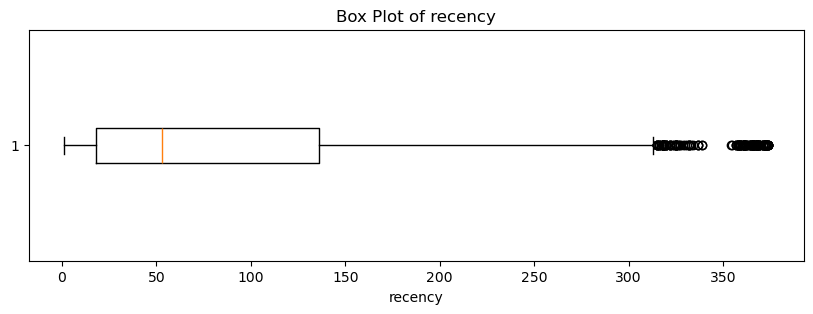

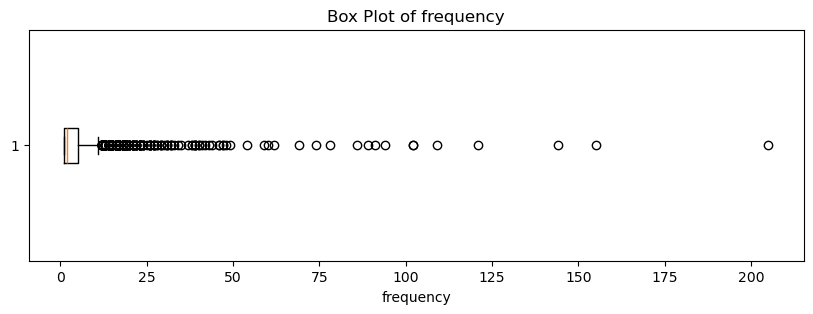

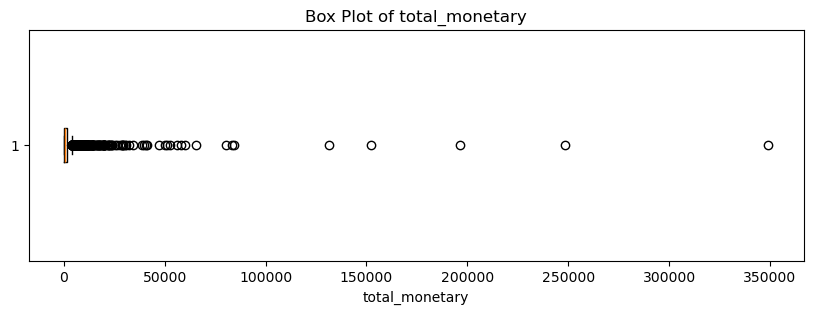

In [38]:
# Select the RFM metrics for outlier analysis.
columns = ["recency", "frequency", "total_monetary"]

# Create a separate box plot for each RFM metric.
for column in columns:
    plt.figure(figsize=(10, 3))
    plt.boxplot(rfm[column].to_list(), vert=False)
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)
    plt.show()